[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_amm/BA_L5_amm.ipynb)

# BA_L5_amm: Constant Product against StableSwap

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Marginal price and average slippage of a two-token automated market maker (AMM) pool of 10 million plus 10 million tokens: the constant-product rule xy = k against the StableSwap invariant of Curve with amplification A = 10, 100 and 2000. Analytical and numerical computation, no market data.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

On decentralised exchanges the price is set by an **automated market maker** (AMM): a smart contract that holds two (or more) tokens and trades along a fixed curve.

**Constant product.** A pool holds $x$ of token X and $y$ of token Y and every trade keeps $x\,y = k$; the marginal price of X in Y is $p = y/x$. Selling $\Delta x$ returns $\Delta y = y\,\Delta x / (x + \Delta x)$.

**StableSwap** ([Egorov, 2019](https://curve.fi/files/stableswap-paper.pdf)). For $n$ coins with balances $x_i$ and amplification coefficient $A$,

$$ A\,n^n \sum_i x_i + D = A\,D\,n^n + \frac{D^{n+1}}{n^n \prod_i x_i}, $$

where $D$ is the total balance when the pool is balanced at a price of 1. As $A \to 0$ it becomes the constant product; as $A \to \infty$ the constant sum $x + y = D$.
For two coins we solve the invariant numerically for $y$ given $x$; the marginal price follows from the implicit function theorem, $p = -dy/dx = F_x / F_y$.

Left: the marginal price of X as a function of its share in the pool. Right: the average slippage $1 - \Delta y / \Delta x$ of a sale of X into a pool of 10 million (m) X and 10 m Y (log scale).

In [5]:
from scipy.optimize import brentq

D0 = 20.0                                      # pool of 10m + 10m


def ss_y(x, A, D=D0):
    """Balance of Y that keeps the 2-coin StableSwap invariant for a balance x of X."""
    f = lambda y: 4 * A * (x + y) + D - 4 * A * D - D ** 3 / (4 * x * y)
    return brentq(f, 1e-12, 10 * D)


def ss_price(x, A, D=D0):
    """Marginal price of X in units of Y, -dy/dx."""
    y = ss_y(x, A, D)
    Fx = 4 * A + D ** 3 / (4 * x ** 2 * y)
    Fy = 4 * A + D ** 3 / (4 * x * y ** 2)
    return Fx / Fy, y

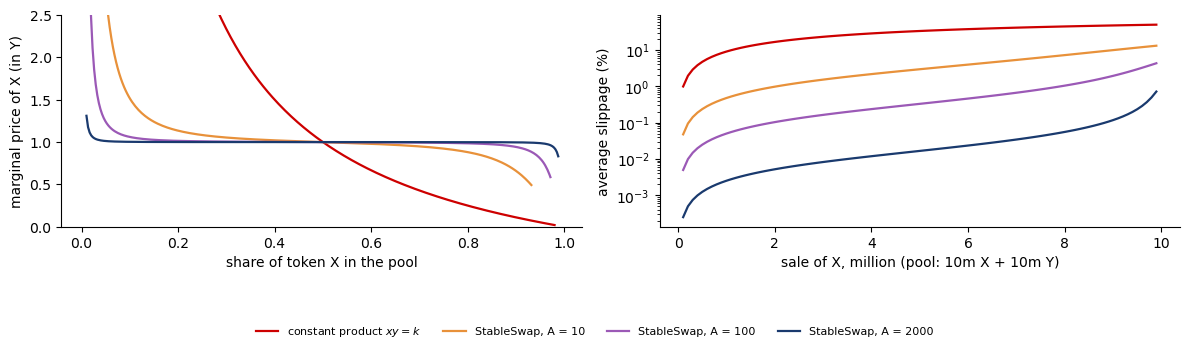

In [6]:
shares = np.linspace(0.02, 0.98, 300)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(shares, (1 - shares) / shares, color=RED, lw=1.6, label='constant product $xy = k$')
for A, col in [(10, BTC), (100, ETH), (2000, BLUE)]:
    pts = []
    for x in np.linspace(0.2, 19.8, 300):
        p, y = ss_price(x, A)
        pts.append((x / (x + y), p))
    pts = np.array(pts)
    ax[0].plot(pts[:, 0], pts[:, 1], lw=1.6, color=col, label=f'StableSwap, A = {A}')
ax[0].set_xlabel('share of token X in the pool'); ax[0].set_ylabel('marginal price of X (in Y)'); ax[0].set_ylim(0, 2.5)
qs = np.linspace(0.1, 9.9, 100)
ax[1].plot(qs, [100 * (1 - (10 - 100 / (10 + q)) / q) for q in qs], color=RED, lw=1.6)
for A, col in [(10, BTC), (100, ETH), (2000, BLUE)]:
    ax[1].plot(qs, [100 * (1 - (10 - ss_y(10 + q, A)) / q) for q in qs], color=col, lw=1.6)
ax[1].set_xlabel('sale of X, million (pool: 10m X + 10m Y)'); ax[1].set_ylabel('average slippage (%)'); ax[1].set_yscale('log')
save(fig, 'ba_l5_amm', 0.17, ncol=4)

## Key numbers

In [7]:
for A in [100, 2000]:
    for s_target in [0.8, 0.9, 0.95]:
        x = brentq(lambda x: x / (x + ss_y(x, A)) - s_target, 10.0, 19.99)
        print(f'A = {A}: marginal price of X when X is {s_target:.0%} of the pool = {ss_price(x, A)[0]:.3f}')
tab = {}
for q in [0.1, 1, 5, 8, 9.5]:
    row = {'constant product': 10 - 100 / (10 + q)}
    for A in [10, 100, 2000]:
        row[f'StableSwap A = {A}'] = 10 - ss_y(10 + q, A)
    tab[f'{q}m'] = {k: 100 * (1 - val / q) for k, val in row.items()}
print('\nAverage slippage (%) for a sale of X into a pool of 10m X + 10m Y:')
pd.DataFrame(tab).T.rename_axis('size of the sale').round(3)

A = 100: marginal price of X when X is 80% of the pool = 0.986
A = 100: marginal price of X when X is 90% of the pool = 0.943
A = 100: marginal price of X when X is 95% of the pool = 0.807
A = 2000: marginal price of X when X is 80% of the pool = 0.999
A = 2000: marginal price of X when X is 90% of the pool = 0.997
A = 2000: marginal price of X when X is 95% of the pool = 0.988

Average slippage (%) for a sale of X into a pool of 10m X + 10m Y:


,constant product,StableSwap A = 10,StableSwap A = 100,StableSwap A = 2000
size of the sale,,,,
0.1m,0.990,0.048,0.005,0.000
1m,9.091,0.478,0.050,0.003
5m,33.333,2.951,0.329,0.017
8m,44.444,7.221,1.042,0.055
9.5m,48.718,11.592,2.938,0.232


**How to read it:** StableSwap is thousands of times cheaper than the constant product near balance, but its slippage rises steeply when the pool empties of one coin.
The price of X stays near 1 even when X makes up most of the pool: the *price* hides the stress, while the *composition* of the pool shows it.